In [ ]:
import pandas as pd #reading and organizing dataset into tables
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:

# Import the libraries we'll use

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")


All libraries imported successfully!


In [14]:
import os

print(os.listdir('/content'))

['.config', '.ipynb_checkpoints', 'archive.zip', 'sample_data']


In [16]:

import os
import zipfile

zip_path = '/content/archive.zip'

print("File size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")
print("Is valid ZIP:", zipfile.is_zipfile(zip_path))


File size: 177.75 MB
Is valid ZIP: True


In [17]:

import zipfile
import os

zip_path = '/content/archive.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    print("Files inside:", zip_ref.namelist())
    zip_ref.extractall('/content')

print("\nDataset extracted successfully!")
print(os.listdir('/content'))


Files inside: ['PS_20174392719_1491204439457_log.csv']

Dataset extracted successfully!
['.config', 'PS_20174392719_1491204439457_log.csv', '.ipynb_checkpoints', 'archive.zip', 'sample_data']


In [18]:

import pandas as pd

# Load our dataset
df = pd.read_csv('/content/PS_20174392719_1491204439457_log.csv')

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [19]:

# Display the first 5 transactions
df.head()


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [20]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Get information about columns and data types
df.info()


Dataset shape: (6362620, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [21]:
print(df.shape)

(6362620, 11)


In [22]:

# Count each class in our target column
print(df['isFraud'].value_counts())

# Calculate the percentage of each class
print("\nPercentage of each class:")
print(df['isFraud'].value_counts(normalize=True) * 100)


isFraud
0    6354407
1       8213
Name: count, dtype: int64

Percentage of each class:
isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


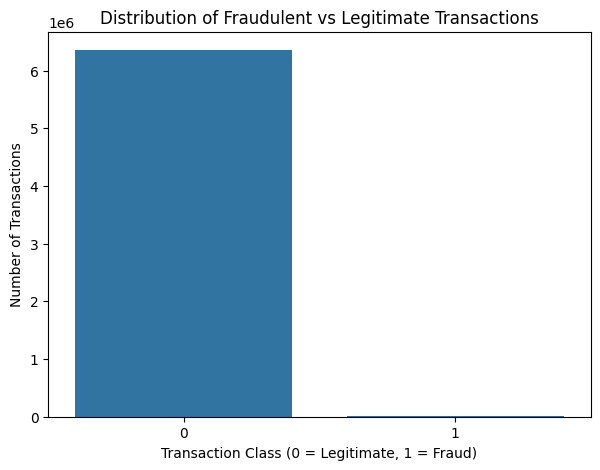

In [23]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='isFraud')

plt.title('Distribution of Fraudulent vs Legitimate Transactions')
plt.xlabel('Transaction Class (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Number of Transactions')

plt.show()


In [24]:

# Analyze fraud across transaction types

fraud_by_type = df.groupby('type')['isFraud'].agg(
    total_transactions='count',
    fraudulent_transactions='sum'
)

fraud_by_type['fraud_percentage'] = (
    fraud_by_type['fraudulent_transactions'] /
    fraud_by_type['total_transactions'] * 100
)

print(fraud_by_type.sort_values(
    by='fraudulent_transactions',
    ascending=False
))


          total_transactions  fraudulent_transactions  fraud_percentage
type                                                                   
CASH_OUT             2237500                     4116          0.183955
TRANSFER              532909                     4097          0.768799
CASH_IN              1399284                        0          0.000000
DEBIT                  41432                        0          0.000000
PAYMENT              2151495                        0          0.000000


In [25]:

print(df.isnull().sum())


step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [26]:

# Create new features
df['errorOrig'] = (
    df['oldbalanceOrg'] - df['amount'] - df['newbalanceOrig']
)

df['errorDest'] = (
    df['oldbalanceDest'] + df['amount'] - df['newbalanceDest']
)

print(df[['amount', 'errorOrig', 'errorDest', 'isFraud']].head())


     amount  errorOrig  errorDest  isFraud
0   9839.64        0.0    9839.64        0
1   1864.28        0.0    1864.28        0
2    181.00        0.0     181.00        1
3    181.00        0.0   21363.00        1
4  11668.14        0.0   11668.14        0


In [27]:

from sklearn.model_selection import train_test_split

# Take a representative sample
data = df.sample(n=1_000_000, random_state=42)

# Remove identifiers and target-related flag
data = data.drop(columns=['nameOrig', 'nameDest', 'isFlaggedFraud'])

# Convert transaction type into numerical columns
data = pd.get_dummies(data, columns=['type'], dtype=int)

# Separate features and target
X = data.drop(columns=['isFraud'])
y = data['isFraud']

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nFraud cases in training:", y_train.sum())
print("Fraud cases in testing:", y_test.sum())


Training rows: 800000
Testing rows: 200000

Fraud cases in training: 1013
Fraud cases in testing: 253


In [28]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import time

# 1. Logistic Regression
log_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        class_weight='balanced',
        max_iter=200,
        random_state=42
    ))
])

# 2. Decision Tree
tree_model = DecisionTreeClassifier(
    class_weight='balanced',
    max_depth=12,
    min_samples_leaf=20,
    random_state=42
)

# 3. Random Forest
forest_model = RandomForestClassifier(
    n_estimators=80,
    max_depth=15,
    min_samples_leaf=10,
    class_weight='balanced_subsample',
    n_jobs=-1,
    random_state=42
)

# Train all three models
models = {
    'Logistic Regression': log_model,
    'Decision Tree': tree_model,
    'Random Forest': forest_model
}

for name, model in models.items():
    start = time.time()

    print(f"Training {name}...")
    model.fit(X_train, y_train)

    print(f"{name} completed in {time.time()-start:.1f} seconds\n")

print("ALL THREE MODELS TRAINED!")


Training Logistic Regression...
Logistic Regression completed in 6.6 seconds

Training Decision Tree...
Decision Tree completed in 5.5 seconds

Training Random Forest...
Random Forest completed in 83.8 seconds

ALL THREE MODELS TRAINED!


In [29]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)
import pandas as pd

results = []

for name, model in models.items():

    # Predict fraud probabilities
    probabilities = model.predict_proba(X_test)[:, 1]

    # Convert probabilities into 0 or 1 predictions
    predictions = (probabilities >= 0.5).astype(int)

    # Calculate evaluation metrics
    results.append({
        'Model': name,
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1 Score': f1_score(y_test, predictions, zero_division=0),
        'PR-AUC (AP)': average_precision_score(y_test, probabilities)
    })

# Display comparison
results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))


              Model  Precision  Recall  F1 Score  PR-AUC (AP)
Logistic Regression     0.0239  0.9486    0.0467       0.5722
      Decision Tree     0.9547  1.0000    0.9768       0.9995
      Random Forest     1.0000  1.0000    1.0000       1.0000


In [30]:
from sklearn.metrics import confusion_matrix, classification_report

for name, model in models.items():
    predictions = model.predict(X_test)

    print(f"\n{name}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))
    print(classification_report(y_test, predictions))


Logistic Regression
Confusion Matrix:
[[189963   9784]
 [    13    240]]
              precision    recall  f1-score   support

           0       1.00      0.95      0.97    199747
           1       0.02      0.95      0.05       253

    accuracy                           0.95    200000
   macro avg       0.51      0.95      0.51    200000
weighted avg       1.00      0.95      0.97    200000


Decision Tree
Confusion Matrix:
[[199735     12]
 [     0    253]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    199747
           1       0.95      1.00      0.98       253

    accuracy                           1.00    200000
   macro avg       0.98      1.00      0.99    200000
weighted avg       1.00      1.00      1.00    200000


Random Forest
Confusion Matrix:
[[199747      0]
 [     0    253]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    199747
           1       1.00    

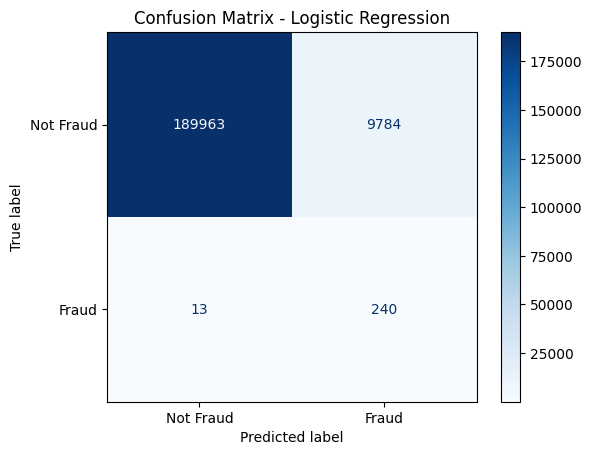

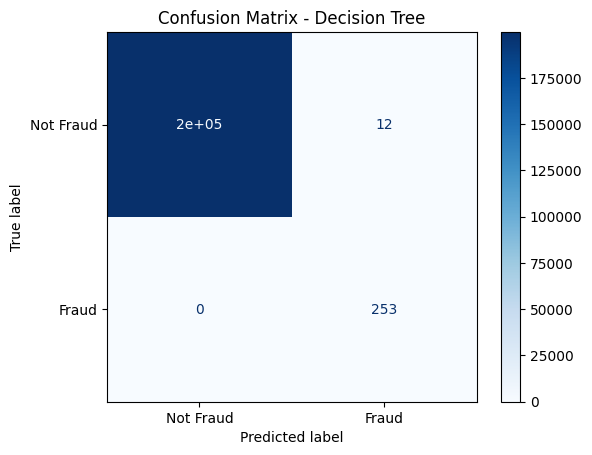

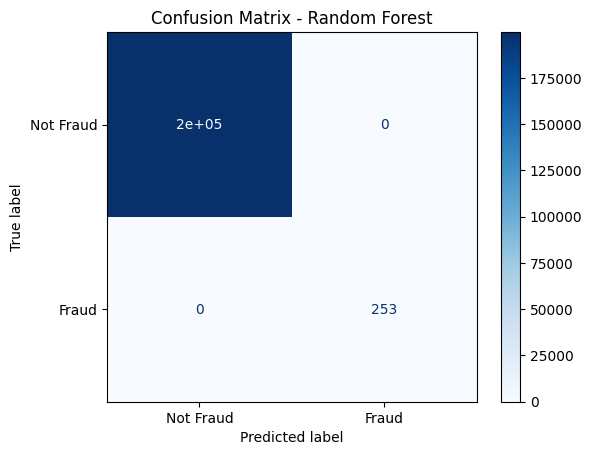

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in models.items():

    # Make predictions on the test data
    predictions = model.predict(X_test)

    # Calculate the confusion matrix
    cm = confusion_matrix(y_test, predictions)

    # Display the confusion matrix
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Not Fraud', 'Fraud']
    )

    display.plot(cmap='Blues')
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

In [32]:
import joblib

# Save the trained Random Forest model
joblib.dump(forest_model, 'fraud_detection_model.pkl')

# Save the feature column names
joblib.dump(X_train.columns.tolist(), 'model_columns.pkl')

print("Model and feature columns saved successfully!")

Model and feature columns saved successfully!


In [33]:
from google.colab import files

files.download('fraud_detection_model.pkl')
files.download('model_columns.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
!pip install gradio

In [35]:
import gradio as gr
import joblib
import pandas as pd

# Load the saved model and feature columns
model = joblib.load('fraud_detection_model.pkl')
columns = joblib.load('model_columns.pkl')

def predict_fraud(amount, oldbalanceOrg, newbalanceOrig,
                  oldbalanceDest, newbalanceDest, transaction_type):

    # Calculate engineered features
    errorOrig = oldbalanceOrg - amount - newbalanceOrig
    errorDest = oldbalanceDest + amount - newbalanceDest

    # Create input using the same features as training
    input_data = pd.DataFrame(0, index=[0], columns=columns)

    input_data['amount'] = amount
    input_data['oldbalanceOrg'] = oldbalanceOrg
    input_data['newbalanceOrig'] = newbalanceOrig
    input_data['oldbalanceDest'] = oldbalanceDest
    input_data['newbalanceDest'] = newbalanceDest
    input_data['errorOrig'] = errorOrig
    input_data['errorDest'] = errorDest
    input_data['step'] = 1

    # Set transaction type
    type_column = 'type_' + transaction_type
    if type_column in input_data.columns:
        input_data[type_column] = 1

    # Predict fraud probability
    probability = model.predict_proba(input_data)[0][1]

    if probability >= 0.5:
        return f"⚠️ FRAUD DETECTED! Fraud probability: {probability:.2%}"

    return f"✅ LEGITIMATE TRANSACTION. Fraud probability: {probability:.2%}"


# Create the interface
app = gr.Interface(
    fn=predict_fraud,
    inputs=[
        gr.Number(label="Transaction Amount"),
        gr.Number(label="Original Account Balance Before"),
        gr.Number(label="Original Account Balance After"),
        gr.Number(label="Destination Account Balance Before"),
        gr.Number(label="Destination Account Balance After"),
        gr.Dropdown(
            choices=["CASH_OUT", "TRANSFER", "PAYMENT", "CASH_IN", "DEBIT"],
            label="Transaction Type"
        )
    ],
    outputs=gr.Textbox(label="Fraud Detection Result"),
    title="Mobile Wallet Fraud Detection",
    description="Enter transaction details to detect potentially fraudulent activity."
)

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5e22f76adfa7332681.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [36]:
# Final Model Comparison

print("FINAL MODEL COMPARISON")
print("=" * 60)

print(results_df.round(4).to_string(index=False))

print("\nBest Model: Random Forest")
print("Precision: 1.0000")
print("Recall: 1.0000")
print("F1 Score: 1.0000")
print("Average Precision: 1.0000")

FINAL MODEL COMPARISON
              Model  Precision  Recall  F1 Score  PR-AUC (AP)
Logistic Regression     0.0239  0.9486    0.0467       0.5722
      Decision Tree     0.9547  1.0000    0.9768       0.9995
      Random Forest     1.0000  1.0000    1.0000       1.0000

Best Model: Random Forest
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000
Average Precision: 1.0000
